In [1]:
%pip install EoN --quiet
import networkx as nx
import EoN
import matplotlib.pyplot as plt
import numpy as np
import random

Note: you may need to restart the kernel to use updated packages.


# Questionário 8

Nesse projeto, vocês devem obter dois plots:
## Epidemias
• Implemente os modelos SI, SIR e SIS em redes do tipo ER, BA e WS $(p=0.001 \text{ e } p=0.01)$ considerando $N = 1000$ e $\braket{k} = 8$.

• Verifique a influência da topologia nas curvas de infectados dos modelos EB, BA, WS $(p=0.001)$, WS $(p= 0.1)$, e BA não-linear $(\alpha =0.5 \text{ e } \alpha = 1.5)$.

In [2]:
def generate_nonlinear_ba(N, m, alpha):
    """Gera uma rede Barabási-Albert não-linear."""
    G = nx.complete_graph(m + 1)
    targets = list(G.nodes())
    
    for i in range(m + 1, N):
        degrees = np.array([G.degree(n) for n in G.nodes()])
        probs = degrees ** alpha
        probs = probs / probs.sum()
        
        # Escolhe m nós baseados na probabilidade k^alpha
        chosen_targets = np.random.choice(G.nodes(), size=m, replace=False, p=probs)
        G.add_node(i)
        for target in chosen_targets:
            G.add_edge(i, target)
    return G

# Parâmetros gerais da rede
N = 1000 # 
k_media = 8 # 
m = k_media // 2  # Para BA, cada novo nó se conecta a m nós (m=4 para grau médio 8)
p_er = k_media / (N - 1) # Probabilidade para a rede ER

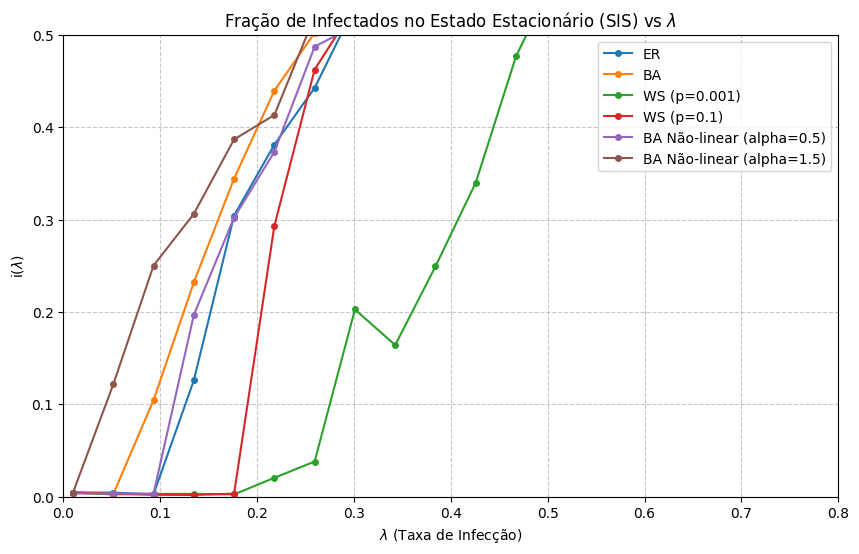

In [6]:
# Definindo as taxas lambda (beta/gamma). Fixamos gamma = 1 e variamos beta (tau)
lambdas = np.linspace(0.01, 0.8, 20)
gamma = 1.0

# 1. Gerar as redes solicitadas
redes = {
    'ER': nx.erdos_renyi_graph(N, p_er),
    'BA': nx.barabasi_albert_graph(N, m),
    'WS (p=0.001)': nx.watts_strogatz_graph(N, k_media, 0.001),
    'WS (p=0.1)': nx.watts_strogatz_graph(N, k_media, 0.1),
    'BA Não-linear (alpha=0.5)': generate_nonlinear_ba(N, m, 0.5),
    'BA Não-linear (alpha=1.5)': generate_nonlinear_ba(N, m, 1.5)
}

# 2. Simulação
resultados = {nome: [] for nome in redes.keys()}
for nome, G in redes.items():
    for lam in lambdas:
        tau = lam * gamma
        # Usando fast_SIS do EoN
        t, S, I = EoN.fast_SIS(G, tau=tau, gamma=gamma, tmax=50, initial_infecteds=range(10))
        # Captura a fração de infectados no estado estacionário (média dos últimos passos)
        fracao_infecciosa_final = np.mean(I[-10:]) / N
        resultados[nome].append(fracao_infecciosa_final)

# 3. Plotando os resultados
plt.figure(figsize=(10, 6))
for nome, i_lam in resultados.items():
    plt.plot(lambdas, i_lam, label=nome, marker='o', markersize=4)

plt.title(r'Fração de Infectados no Estado Estacionário (SIS) vs $\lambda$')
plt.xlabel(r'$\lambda$ (Taxa de Infecção)')
plt.ylabel(r'i($\lambda$)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim([0, 0.8])
plt.ylim([0, 0.5])
plt.show()

## Imunização
Considere o modelo SIR e uma rede BA com 1000 vértices e grau médio 8.

• No modelo SIR, imunize $x%$ de vértices selecionados de forma aleatória.

• Faça um gráfico da fração de recuperados ($r$) versus $x$ ($%$ de imunizados). Realize esse processo 10 vezes e mostre as médias e desvios padrão nesse gráfico.

• Agora imunize os $x%$ maiores hubs e obtenha a mesma curva.

• Coloque os resultados em um mesmo gráfico. Qual tipo de imunização é mais efetiva para conter uma epidemia?

• Basicamente, mostre o gráfico da fração de imunizados ($x$) versus a fração de recuperados ($r$), com duas curvas, uma para a imunização aleatórias e outra para a imunização dos hubs.

Iniciando simulações de Imunização (Parte 2)...


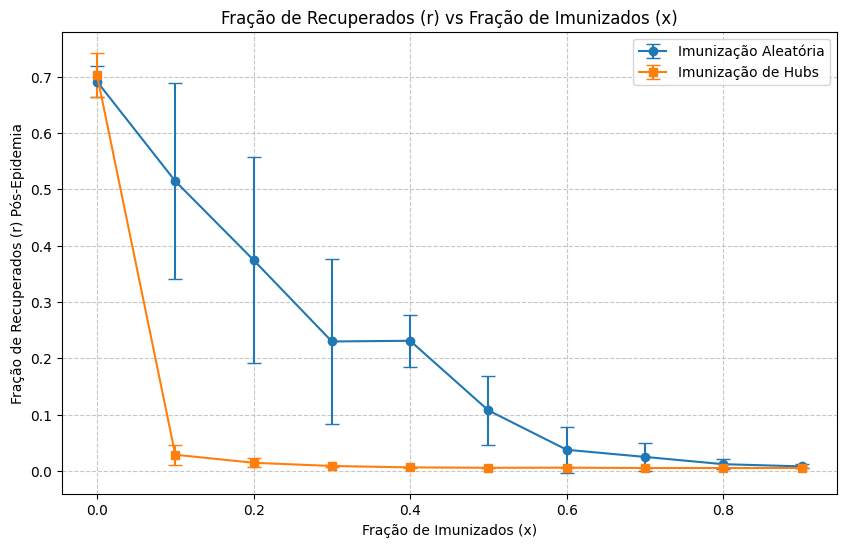

In [7]:
def imunizar_rede(G, fracao_x, estrategia="aleatoria"):
    """Remove uma fração x de nós da rede (imunização) de acordo com a estratégia."""
    G_imune = G.copy()
    num_remover = int(fracao_x * G.number_of_nodes())
    
    if num_remover == 0:
        return G_imune
        
    if estrategia == "aleatoria":
        # Imuniza nós selecionados de forma aleatória
        nos_para_remover = random.sample(list(G_imune.nodes()), num_remover)
    elif estrategia == "hubs":
        # Imuniza os nós de maior grau (hubs
        graus = dict(G_imune.degree())
        nos_ordenados = sorted(graus, key=graus.get, reverse=True)
        nos_para_remover = nos_ordenados[:num_remover]
        
    G_imune.remove_nodes_from(nos_para_remover)
    return G_imune

# Parâmetros
fracoes_x = np.linspace(0, 0.9, 10)
num_simulacoes = 10 # 
tau_sir = 0.3
gamma_sir = 1.0

# Arrays para armazenar resultados
media_aleatoria, std_aleatoria = [], []
media_hubs, std_hubs = [], []

print("Iniciando simulações de Imunização (Parte 2)...")
G_base = nx.barabasi_albert_graph(N, m)

for x in fracoes_x:
    recup_aleatoria_run = []
    recup_hubs_run = []
    
    for _ in range(num_simulacoes):
        # Imunização Aleatória
        G_aleat = imunizar_rede(G_base, x, "aleatoria")
        if G_aleat.number_of_nodes() > 0:
            # Seleciona 5 nós iniciais aleatórios dentre os suscetíveis restantes
            iniciais_aleat = random.sample(list(G_aleat.nodes()), min(5, G_aleat.number_of_nodes()))
            t, S, I, R = EoN.fast_SIR(G_aleat, tau=tau_sir, gamma=gamma_sir, initial_infecteds=iniciais_aleat)
            # Fração de recuperados da epidemia em relação à população TOTAL original
            recup_aleatoria_run.append(R[-1] / N)
        else:
            recup_aleatoria_run.append(0)
            
        # Imunização por Hubs
        G_hubs = imunizar_rede(G_base, x, "hubs")
        if G_hubs.number_of_nodes() > 0:
            iniciais_hubs = random.sample(list(G_hubs.nodes()), min(5, G_hubs.number_of_nodes()))
            t, S, I, R = EoN.fast_SIR(G_hubs, tau=tau_sir, gamma=gamma_sir, initial_infecteds=iniciais_hubs)
            recup_hubs_run.append(R[-1] / N)
        else:
            recup_hubs_run.append(0)
            
    # Salva médias e desvios para o X atual 
    media_aleatoria.append(np.mean(recup_aleatoria_run))
    std_aleatoria.append(np.std(recup_aleatoria_run))
    
    media_hubs.append(np.mean(recup_hubs_run))
    std_hubs.append(np.std(recup_hubs_run))

# Plot final comparativo
plt.figure(figsize=(10, 6))

plt.errorbar(fracoes_x, media_aleatoria, yerr=std_aleatoria, fmt='-o', 
             label='Imunização Aleatória', capsize=5)
plt.errorbar(fracoes_x, media_hubs, yerr=std_hubs, fmt='-s', 
             label='Imunização de Hubs', capsize=5)

plt.title('Fração de Recuperados (r) vs Fração de Imunizados (x)')
plt.xlabel('Fração de Imunizados (x)')
plt.ylabel('Fração de Recuperados (r) Pós-Epidemia')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()